# **ANALISIS KELAYAKAN VARIABEL TARGET UNTUK PEMODELAN MULTI-OBJEKTIF**

In [ ]:
# menghubungkan google drive
from google.colab import drive
drive.mount('/content/drive')

print("="*60)
print("GOOGLE DRIVE WAS CONNECTED SUCCESSFULLY")
print("="*60)

Mounted at /content/drive
GOOGLE DRIVE WAS CONNECTED SUCCESSFULLY


### IMPORT LIBRARY

In [ ]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 46.9 MB/s  0:00:02


In [ ]:
# import library dasar
import warnings
warnings.filterwarnings("ignore")

# import library manipulasi data
import numpy as np
import pandas as pd

# import library visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# import library machine learning
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

# import model baseline dan model single
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, AdaBoostRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor

# import pipeline dan scaling untuk model yang sensitif terhadap skala data
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# import library preprocessing
from sklearn.impute import SimpleImputer

# import library xgboost
from xgboost import XGBRegressor

# import library catboost
try:
    from catboost import CatBoostRegressor
except ModuleNotFoundError:
    import sys
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "catboost", "-q"])
    from catboost import CatBoostRegressor

# mengatur tampilan dataframe
pd.set_option("display.max_columns",None)
pd.set_option("display.width",None)
pd.set_option("display.max_colwidth",None)

print("="*60)
print("ALL REQUIRED LIBRARIES WERE IMPORTED SUCCESSFULLY")
print("="*60)


ALL REQUIRED LIBRARIES WERE IMPORTED SUCCESSFULLY


### MEMBACA DATASET DAN MENENTUKAN VARIABEL AWAL

In [ ]:
# menentukan folder penelitian
project_path="/content/drive/MyDrive/dataset"

# menentukan lokasi dataset
file_path=f"{project_path}/raw-dataset_fix.xlsx"

# membaca dataset
df=pd.read_excel(file_path,sheet_name="raw_data")

# menentukan variabel target utama
default_target="Potential_biogas_day"

print("="*60)
print("DATASET WAS LOADED SUCCESSFULLY")
print("="*60)
print(f"Dataset Shape      : {df.shape}")
print(f"Number of Rows     : {df.shape[0]}")
print(f"Number of Columns  : {df.shape[1]}")
print(f"Worksheet          : raw_data")
print(f"Default Target     : {default_target}")
print("="*60)

# menampilkan lima data pertama
display(df.head())

DATASET WAS LOADED SUCCESSFULLY
Dataset Shape      : (774, 30)
Number of Rows     : 774
Number of Columns  : 30
Worksheet          : raw_data
Default Target     : Potential_biogas_day


,year,district,subdistrict,beef_cattle,dairy_cattle,layer_chickens,broiler_chickens,total_ekor_sapi_perah,total_ekor_sapi_daging,total_ekor_ayam_petelur,total_ekor_ayam_pedaging,Manure_per_animal_sapiPerah,Manure_per_animal_sapiPotong,manure_per_animal_chicken_layer,manure_per_animal_chicken_potong,total_manure_potential_day_cattle_kg,total_manure_potential_year_cattle_ton,total_manure_potential_day_chicken_kg,total_manure_potential_year_chicken_ton,non_industrial_feed,mixed_feed,industrial_feed,average_temperature_per_district,humidity,Average_daily_rainfall,total_rainfall,crude_oil_price_usd_avg,usd_idr_avg,energy_price_proxy_idr,Potential_biogas_day
0,2023,Kabupaten Purwakarta,Jatiluhur,0,28,3,2,0,111.0,2230,10060,"50,3","41,7","0,068","0,086",4628.7,1689.4755,1016.800,371.13200,554.0,363.0,22,26.701,80.622,4.183,1526.8,68.106032,14310.539586,974634.066905,2.431677
1,2023,Kabupaten Purwakarta,Sukasari,0,73,1,2,0,220.0,50,10000,"50,3","41,7","0,068","0,086",9174.0,3348.5100,863.400,315.14100,699.0,51.0,26,22.824,81.016,5.743,2096.2,68.106032,14310.539586,974634.066905,2.869216
2,2023,Kabupaten Purwakarta,Maniis,0,91,6,14,0,223.0,2680,148510,"50,3","41,7","0,068","0,086",9299.1,3394.1715,12954.100,4728.24650,2302.0,240.0,59,26.713,80.208,4.183,1526.8,68.106032,14310.539586,974634.066905,22.127718
3,2023,Kabupaten Purwakarta,Tegal Waru,0,407,3,8,0,1155.0,2012,14980,"50,3","41,7","0,068","0,086",48163.5,17579.6775,1425.096,520.16004,1711.0,487.0,222,26.856,80.225,4.183,1526.8,68.106032,14310.539586,974634.066905,10.187692
4,2023,Kabupaten Purwakarta,Plered,0,46,3,5,0,257.0,500,11250,"50,3","41,7","0,068","0,086",10716.9,3911.6685,1001.500,365.54750,963.0,297.0,16,26.687,80.208,4.183,1526.8,68.106032,14310.539586,974634.066905,3.353098


### INSPEKSI AWAL DATASET

In [ ]:
# menampilkan informasi dataset
print("="*60)
print("DATASET INFORMATION")
print("="*60)
df.info()

# menampilkan ringkasan statistik
print("\n"+"="*60)
print("DESCRIPTIVE STATISTICS")
print("="*60)
display(df.describe(include="all"))

# menghitung missing value
missing_summary=df.isnull().sum().to_frame(name="Missing Values")
missing_summary["Percentage (%)"]=round((missing_summary["Missing Values"]/len(df))*100,2)

print("\n"+"="*60)
print("MISSING VALUE SUMMARY")
print("="*60)
display(missing_summary)

# menghitung data duplikat
duplicate_count=df.duplicated().sum()

print("\n"+"="*60)
print("DUPLICATE DATA SUMMARY")
print("="*60)
print(f"Number of Duplicate Rows : {duplicate_count}")

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 774 entries, 0 to 773
Data columns (total 30 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   year                                     774 non-null    int64  
 1   district                                 774 non-null    object 
 2   subdistrict                              774 non-null    object 
 3   beef_cattle                              774 non-null    object 
 4   dairy_cattle                             774 non-null    int64  
 5   layer_chickens                           774 non-null    int64  
 6   broiler_chickens                         774 non-null    int64  
 7   total_ekor_sapi_perah                    736 non-null    object 
 8   total_ekor_sapi_daging                   769 non-null    float64
 9   total_ekor_ayam_petelur                  754 non-null    object 
 10  total_ekor_ayam_pedaging      

,year,district,subdistrict,beef_cattle,dairy_cattle,layer_chickens,broiler_chickens,total_ekor_sapi_perah,total_ekor_sapi_daging,total_ekor_ayam_petelur,total_ekor_ayam_pedaging,Manure_per_animal_sapiPerah,Manure_per_animal_sapiPotong,manure_per_animal_chicken_layer,manure_per_animal_chicken_potong,total_manure_potential_day_cattle_kg,total_manure_potential_year_cattle_ton,total_manure_potential_day_chicken_kg,total_manure_potential_year_chicken_ton,non_industrial_feed,mixed_feed,industrial_feed,average_temperature_per_district,humidity,Average_daily_rainfall,total_rainfall,crude_oil_price_usd_avg,usd_idr_avg,energy_price_proxy_idr,Potential_biogas_day
count,774.000000,774,774,774.0,774.000000,774.000000,774.000000,736.0,769.000000,754.0,747.0,774,774,774,774,774.000000,774.000000,7.740000e+02,774.000000,774.000000,774.000000,774.000000,774.000000,774.000000,774.000000,774.000000,774.000000,774.000000,7.740000e+02,774.000000
unique,NaN,9,251,81.0,NaN,NaN,NaN,147.0,NaN,435.0,540.0,1,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Cirebon,Pasawahan,0.0,NaN,NaN,NaN,0.0,NaN,0.0,0.0,"50,3","41,7","0,068","0,086",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,120,6,620.0,NaN,NaN,NaN,424.0,NaN,241.0,150.0,774,774,774,774,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,2022.000000,NaN,NaN,NaN,17.596899,2.622739,3.927649,NaN,552.000034,NaN,NaN,NaN,NaN,NaN,NaN,33400.505563,12191.184530,4.118169e+04,15031.316225,260.600076,135.604832,17.414729,24.482062,84.669448,7.361531,2686.929457,80.011542,14794.172300,1.185508e+06,99.099037
std,0.817025,NaN,NaN,NaN,81.241851,7.148204,11.349211,NaN,1322.252976,NaN,NaN,NaN,NaN,NaN,NaN,81574.419832,29774.663239,1.388520e+05,50680.978474,724.235027,327.082328,38.088884,2.016935,3.476052,2.001278,730.468963,10.848767,376.719791,1.738610e+05,265.185346
min,2021.000000,NaN,NaN,NaN,0.000000,0.000000,0.000000,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,15.364000,74.353000,3.115000,1136.800000,68.106032,14310.539586,9.746341e+05,0.000000
25%,2021.000000,NaN,NaN,NaN,0.000000,0.000000,0.000000,NaN,84.000000,NaN,NaN,NaN,NaN,NaN,NaN,2397.750000,875.178750,1.644849e+00,0.600370,0.000000,0.000000,0.000000,23.238250,82.024000,6.078000,2218.600000,68.106032,14310.539586,9.746341e+05,2.213249
50%,2022.000000,NaN,NaN,NaN,0.000000,0.000000,0.000000,NaN,230.000000,NaN,NaN,NaN,NaN,NaN,NaN,10354.600000,3779.429000,1.470145e+03,536.602925,0.000000,0.000000,0.000000,24.811500,85.448000,7.185000,2622.500000,77.597120,14843.177310,1.181711e+06,10.520139
75%,2023.000000,NaN,NaN,NaN,1.000000,2.000000,3.000000,NaN,538.000000,NaN,NaN,NaN,NaN,NaN,NaN,28856.400000,10532.586000,2.205908e+04,8051.563287,154.250000,133.000000,18.750000,26.078500,87.242000,8.617250,3145.225000,94.331474,15228.800004,1.400179e+06,77.182614



MISSING VALUE SUMMARY


,Missing Values,Percentage (%)
year,0,0.00
district,0,0.00
subdistrict,0,0.00
beef_cattle,0,0.00
dairy_cattle,0,0.00
layer_chickens,0,0.00
broiler_chickens,0,0.00
total_ekor_sapi_perah,38,4.91
total_ekor_sapi_daging,5,0.65
total_ekor_ayam_petelur,20,2.58



DUPLICATE DATA SUMMARY
Number of Duplicate Rows : 0


### IDENTIFIKASI STRUKTUR DATASET

In [ ]:
# membuat ringkasan struktur dataset
dataset_structure=pd.DataFrame({
    "Variable":df.columns,
    "Original Data Type":df.dtypes.astype(str)
})

print("="*60)
print("DATASET STRUCTURE")
print("="*60)
print(f"Number of Variables : {len(dataset_structure)}")
print(f"Number of Records   : {len(df)}")
print("="*60)

# menampilkan struktur dataset
display(dataset_structure)

DATASET STRUCTURE
Number of Variables : 30
Number of Records   : 774


,Variable,Original Data Type
year,year,int64
district,district,object
subdistrict,subdistrict,object
beef_cattle,beef_cattle,object
dairy_cattle,dairy_cattle,int64
layer_chickens,layer_chickens,int64
broiler_chickens,broiler_chickens,int64
total_ekor_sapi_perah,total_ekor_sapi_perah,object
total_ekor_sapi_daging,total_ekor_sapi_daging,float64
total_ekor_ayam_petelur,total_ekor_ayam_petelur,object


### VALIDASI STRUKTUR DAN KUALITAS DATASET

In [ ]:
# membuat fungsi konversi numerik cerdas
def smart_numeric_converter(series):

    # apabila sudah bertipe numerik
    if pd.api.types.is_numeric_dtype(series):
        return series

    # mengubah menjadi string
    series=series.astype(str).str.strip()

    # mengubah nilai kosong menjadi nan
    series=series.replace(
        [""," ","nan","None","NULL","null","-"],
        np.nan
    )

    # menghapus spasi
    series=series.str.replace(" ","",regex=False)

    # mendeteksi format angka indonesia
    contains_comma=series.str.contains(",",regex=False,na=False).any()

    if contains_comma:
        series=series.str.replace(".", "", regex=False)
        series=series.str.replace(",", ".", regex=False)

    # mengubah menjadi numerik
    return pd.to_numeric(series,errors="coerce")

In [ ]:
# membuat salinan dataset
df_validated=df.copy()

# menentukan ambang batas identifikasi numerik
numeric_threshold=80

# menghitung missing value
missing_count=df_validated.isnull().sum()

# menghitung persentase missing value
missing_percentage=(missing_count/len(df_validated)*100).round(2)

# menyiapkan variabel
candidate_numeric_columns=[]
categorical_columns=[]
converted_columns=[]
validation_result=[]

# melakukan validasi seluruh kolom
for column in df_validated.columns:

    original_dtype=str(df_validated[column].dtype)

    converted=smart_numeric_converter(df_validated[column])

    numeric_ratio=round(converted.notna().mean()*100,2)

    if numeric_ratio>=numeric_threshold:

        df_validated[column]=converted

        candidate_numeric_columns.append(column)

        if original_dtype=="object":
            converted_columns.append(column)

        validated_dtype=str(df_validated[column].dtype)

        status="Candidate Numeric"

    else:

        categorical_columns.append(column)

        validated_dtype=original_dtype

        status="Categorical"

    validation_result.append([
        column,
        original_dtype,
        validated_dtype,
        missing_count[column],
        missing_percentage[column],
        numeric_ratio,
        status
    ])

# membuat ringkasan validasi
validation_summary=pd.DataFrame(
    validation_result,
    columns=[
        "Variable",
        "Original Data Type",
        "Validated Data Type",
        "Missing Values",
        "Missing Percentage (%)",
        "Numeric Ratio (%)",
        "Status"
    ]
)

print("="*70)
print("DATASET VALIDATION COMPLETED SUCCESSFULLY")
print("="*70)

display(validation_summary)

print("="*70)
print("VALIDATION RESULT")
print("="*70)
print(f"Candidate Numerical Variables : {len(candidate_numeric_columns)}")
print(f"Categorical Variables         : {len(categorical_columns)}")
print(f"Object Columns Converted      : {len(converted_columns)}")
print(f"Variables with Missing Values : {(missing_count>0).sum()}")

print("\nConverted Columns")
print("-"*70)

if len(converted_columns)==0:
    print("None")
else:
    for column in converted_columns:
        print(column)

print("\nCategorical Variables")
print("-"*70)

for column in categorical_columns:
    print(column)

print("\n"+"="*70)
print("VALIDATED DATA TYPE")
print("="*70)

display(df_validated.dtypes.to_frame(name="Data Type"))

DATASET VALIDATION COMPLETED SUCCESSFULLY


,Variable,Original Data Type,Validated Data Type,Missing Values,Missing Percentage (%),Numeric Ratio (%),Status
0,year,int64,int64,0,0.00,100.00,Candidate Numeric
1,district,object,object,0,0.00,0.00,Categorical
2,subdistrict,object,object,0,0.00,0.00,Categorical
3,beef_cattle,object,float64,0,0.00,99.87,Candidate Numeric
4,dairy_cattle,int64,int64,0,0.00,100.00,Candidate Numeric
5,layer_chickens,int64,int64,0,0.00,100.00,Candidate Numeric
6,broiler_chickens,int64,int64,0,0.00,100.00,Candidate Numeric
7,total_ekor_sapi_perah,object,float64,38,4.91,90.31,Candidate Numeric
8,total_ekor_sapi_daging,float64,float64,5,0.65,99.35,Candidate Numeric
9,total_ekor_ayam_petelur,object,float64,20,2.58,96.12,Candidate Numeric


VALIDATION RESULT
Candidate Numerical Variables : 28
Categorical Variables         : 2
Object Columns Converted      : 8
Variables with Missing Values : 4

Converted Columns
----------------------------------------------------------------------
beef_cattle
total_ekor_sapi_perah
total_ekor_ayam_petelur
total_ekor_ayam_pedaging
Manure_per_animal_sapiPerah
Manure_per_animal_sapiPotong
manure_per_animal_chicken_layer
manure_per_animal_chicken_potong

Categorical Variables
----------------------------------------------------------------------
district
subdistrict

VALIDATED DATA TYPE


,Data Type
year,int64
district,object
subdistrict,object
beef_cattle,float64
dairy_cattle,int64
layer_chickens,int64
broiler_chickens,int64
total_ekor_sapi_perah,float64
total_ekor_sapi_daging,float64
total_ekor_ayam_petelur,float64


### DATA PREPROCESSING

In [ ]:
# membuat salinan dataset tervalidasi
df_clean=df_validated.copy()

# menghapus data duplikat
df_clean=df_clean.drop_duplicates().reset_index(drop=True)

# mengisi missing value menggunakan median
for column in candidate_numeric_columns:

    if df_clean[column].isnull().sum()>0:

        median_value=df_clean[column].median()

        df_clean[column]=df_clean[column].fillna(median_value)

# membuat ringkasan preprocessing
preprocessing_summary=pd.DataFrame({
    "Variable":df_clean.columns,
    "Data Type":df_clean.dtypes.astype(str),
    "Missing Values":df_clean.isnull().sum().values
})

print("="*70)
print("DATA PREPROCESSING COMPLETED SUCCESSFULLY")
print("="*70)
print(f"Dataset Shape             : {df_clean.shape}")
print(f"Remaining Missing Values  : {df_clean.isnull().sum().sum()}")
print(f"Remaining Duplicate Rows  : {df_clean.duplicated().sum()}")
print(f"Numerical Variables       : {len(candidate_numeric_columns)}")
print(f"Categorical Variables     : {len(categorical_columns)}")

print("\n"+"="*70)
print("PREPROCESSING SUMMARY")
print("="*70)

display(preprocessing_summary)

DATA PREPROCESSING COMPLETED SUCCESSFULLY
Dataset Shape             : (774, 30)
Remaining Missing Values  : 0
Remaining Duplicate Rows  : 0
Numerical Variables       : 28
Categorical Variables     : 2

PREPROCESSING SUMMARY


,Variable,Data Type,Missing Values
year,year,int64,0
district,district,object,0
subdistrict,subdistrict,object,0
beef_cattle,beef_cattle,float64,0
dairy_cattle,dairy_cattle,int64,0
layer_chickens,layer_chickens,int64,0
broiler_chickens,broiler_chickens,int64,0
total_ekor_sapi_perah,total_ekor_sapi_perah,float64,0
total_ekor_sapi_daging,total_ekor_sapi_daging,float64,0
total_ekor_ayam_petelur,total_ekor_ayam_petelur,float64,0


### PERSIAPAN EVALUASI KANDIDAT VARIABEL TARGET

In [ ]:
# menentukan target utama
fixed_target="Potential_biogas_day"

# menentukan jumlah minimum nilai unik
minimum_unique_values=5

# membuat daftar kandidat target
candidate_targets=[]

# membuat daftar variabel yang dieliminasi
excluded_targets=[]

# melakukan seleksi kandidat target
for target in candidate_numeric_columns:

    # melewati target utama
    if target==fixed_target:

        continue

    # menghitung jumlah nilai unik
    unique_values=df_clean[target].nunique()

    # menghitung variansi
    variance=df_clean[target].var()

    # mengecek jumlah nilai unik
    if unique_values<minimum_unique_values:

        excluded_targets.append({
            "Variable":target,
            "Reason":"Insufficient Unique Values"
        })

        continue

    # mengecek variansi
    if variance<=0:

        excluded_targets.append({
            "Variable":target,
            "Reason":"Zero Variance"
        })

        continue

    # menentukan variabel prediktor
    predictor_columns=[
        column
        for column in candidate_numeric_columns
        if column!=target
    ]

    # membentuk variabel x dan y
    x=df_clean[predictor_columns]

    y=df_clean[target]

    # membagi data training dan testing
    x_train,x_test,y_train,y_test=train_test_split(
        x,
        y,
        test_size=0.20,
        random_state=42,
        shuffle=True
    )

    # menyimpan kandidat target
    candidate_targets.append({

        "Target":target,

        "Predictors":predictor_columns,

        "X Train":x_train,
        "X Test":x_test,

        "Y Train":y_train,
        "Y Test":y_test

    })

print("="*70)
print("CANDIDATE TARGET SELECTION COMPLETED SUCCESSFULLY")
print("="*70)
print(f"Fixed Target (Y1)              : {fixed_target}")
print(f"Additional Candidate Targets   : {len(candidate_targets)}")
print(f"Excluded Variables             : {len(excluded_targets)}")
print(f"Training Ratio                 : 80%")
print(f"Testing Ratio                  : 20%")

print("\n"+"="*70)
print("ADDITIONAL CANDIDATE TARGETS")
print("="*70)

for index,item in enumerate(candidate_targets,start=1):

    print(f"{index:02d}. {item['Target']}")

print("\n"+"="*70)
print("EXCLUDED VARIABLES")
print("="*70)

if len(excluded_targets)==0:

    print("No variables were excluded.")

else:

    excluded_summary=pd.DataFrame(excluded_targets)

    display(excluded_summary)

CANDIDATE TARGET SELECTION COMPLETED SUCCESSFULLY
Fixed Target (Y1)              : Potential_biogas_day
Additional Candidate Targets   : 19
Excluded Variables             : 8
Training Ratio                 : 80%
Testing Ratio                  : 20%

ADDITIONAL CANDIDATE TARGETS
01. beef_cattle
02. dairy_cattle
03. layer_chickens
04. broiler_chickens
05. total_ekor_sapi_perah
06. total_ekor_sapi_daging
07. total_ekor_ayam_petelur
08. total_ekor_ayam_pedaging
09. total_manure_potential_day_cattle_kg
10. total_manure_potential_year_cattle_ton
11. total_manure_potential_day_chicken_kg
12. total_manure_potential_year_chicken_ton
13. non_industrial_feed
14. mixed_feed
15. industrial_feed
16. average_temperature_per_district
17. humidity
18. Average_daily_rainfall
19. total_rainfall

EXCLUDED VARIABLES


,Variable,Reason
0,year,Insufficient Unique Values
1,Manure_per_animal_sapiPerah,Insufficient Unique Values
2,Manure_per_animal_sapiPotong,Insufficient Unique Values
3,manure_per_animal_chicken_layer,Insufficient Unique Values
4,manure_per_animal_chicken_potong,Insufficient Unique Values
5,crude_oil_price_usd_avg,Insufficient Unique Values
6,usd_idr_avg,Insufficient Unique Values
7,energy_price_proxy_idr,Insufficient Unique Values


### EVALUASI MODEL LINEAR REGRESSION

In [ ]:
# membuat daftar hasil evaluasi linear regression
linear_result=[]

# melakukan evaluasi setiap kandidat target
for item in candidate_targets:

    # mengambil informasi dataset
    target=item["Target"]

    x_train=item["X Train"]
    x_test=item["X Test"]

    y_train=item["Y Train"]
    y_test=item["Y Test"]

    # membangun model linear regression
    linear_model=LinearRegression()

    # melatih model
    linear_model.fit(x_train,y_train)

    # melakukan prediksi
    prediction=linear_model.predict(x_test)

    # menghitung metrik evaluasi
    r2=r2_score(y_test,prediction)
    mae=mean_absolute_error(y_test,prediction)
    rmse=np.sqrt(mean_squared_error(y_test,prediction))

    # menyimpan hasil evaluasi
    linear_result.append({

        "Target":target,
        "Linear R²":r2,
        "Linear MAE":mae,
        "Linear RMSE":rmse

    })

# mengubah hasil menjadi dataframe
linear_result=pd.DataFrame(linear_result)

# mengurutkan berdasarkan nilai r2 tertinggi
linear_result=linear_result.sort_values(
    by="Linear R²",
    ascending=False
).reset_index(drop=True)

print("="*70)
print("LINEAR REGRESSION EVALUATION COMPLETED SUCCESSFULLY")
print("="*70)
print(f"Evaluated Candidate Targets : {len(linear_result)}")

print("\n"+"="*70)
print("LINEAR REGRESSION RESULT")
print("="*70)

display(linear_result)

LINEAR REGRESSION EVALUATION COMPLETED SUCCESSFULLY
Evaluated Candidate Targets : 19

LINEAR REGRESSION RESULT


,Target,Linear R²,Linear MAE,Linear RMSE
0,total_manure_potential_day_cattle_kg,1.000000,9.762017e-11,1.971904e-10
1,total_manure_potential_day_chicken_kg,1.000000,3.918838e-11,1.233359e-10
2,total_manure_potential_year_cattle_ton,1.000000,2.589635e-11,5.392253e-11
3,total_manure_potential_year_chicken_ton,1.000000,4.669343e-11,1.146931e-10
4,total_rainfall,1.000000,9.153027e-02,1.077087e-01
5,Average_daily_rainfall,1.000000,2.507715e-04,2.950913e-04
6,total_ekor_ayam_pedaging,0.998887,2.126851e+04,7.288467e+04
7,total_ekor_sapi_perah,0.897679,8.542092e+01,4.126414e+02
8,industrial_feed,0.833041,9.070768e+00,1.692261e+01
9,mixed_feed,0.797927,8.122232e+01,1.661971e+02


### EVALUASI MODEL XGBOOST

In [ ]:
# membuat daftar hasil evaluasi xgboost
xgboost_result=[]

# melakukan evaluasi setiap kandidat target
for item in candidate_targets:

    # mengambil informasi dataset
    target=item["Target"]

    x_train=item["X Train"]
    x_test=item["X Test"]

    y_train=item["Y Train"]
    y_test=item["Y Test"]

    # membangun model xgboost
    xgb_model=XGBRegressor(

        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42

    )

    # melatih model
    xgb_model.fit(x_train,y_train)

    # melakukan prediksi
    prediction=xgb_model.predict(x_test)

    # menghitung metrik evaluasi
    r2=r2_score(y_test,prediction)
    mae=mean_absolute_error(y_test,prediction)
    rmse=np.sqrt(mean_squared_error(y_test,prediction))

    # menyimpan hasil evaluasi
    xgboost_result.append({

        "Target":target,
        "XGBoost R²":r2,
        "XGBoost MAE":mae,
        "XGBoost RMSE":rmse

    })

# mengubah hasil menjadi dataframe
xgboost_result=pd.DataFrame(xgboost_result)

print("="*70)
print("XGBOOST EVALUATION COMPLETED SUCCESSFULLY")
print("="*70)
print(f"Evaluated Candidate Targets : {len(xgboost_result)}")

print("\n"+"="*70)
print("XGBOOST RESULT")
print("="*70)

display(xgboost_result)

XGBOOST EVALUATION COMPLETED SUCCESSFULLY
Evaluated Candidate Targets : 19

XGBOOST RESULT


,Target,XGBoost R²,XGBoost MAE,XGBoost RMSE
0,beef_cattle,0.441532,39.477930,223.233116
1,dairy_cattle,0.865030,10.905568,42.874731
2,layer_chickens,0.749037,1.411489,4.472416
3,broiler_chickens,0.205815,3.796584,17.236259
4,total_ekor_sapi_perah,0.993099,35.392173,107.164734
5,total_ekor_sapi_daging,0.859815,155.620439,494.920604
6,total_ekor_ayam_petelur,0.662860,28007.642519,77352.959234
7,total_ekor_ayam_pedaging,0.984088,78942.038679,275578.909440
8,total_manure_potential_day_cattle_kg,0.961663,4036.585256,16786.006390
9,total_manure_potential_year_cattle_ton,0.961663,1473.354244,6126.893617


EVALUASI MODEL CATBOOST

In [ ]:
# membuat daftar hasil evaluasi xgboost
catboost_result=[]

# melakukan evaluasi setiap kandidat target
for item in candidate_targets:

    # mengambil informasi dataset
    target=item["Target"]

    x_train=item["X Train"]
    x_test=item["X Test"]

    y_train=item["Y Train"]
    y_test=item["Y Test"]

    # membangun model catboost
    catboost_model = CatBoostRegressor(

        iterations=100,
        depth=6,
        learning_rate=0.1,
        loss_function="RMSE",
        random_seed=42,
        verbose=0

    )

    # melatih model
    catboost_model.fit(x_train,y_train)

    # melakukan prediksi
    prediction=catboost_model.predict(x_test)

    # menghitung metrik evaluasi
    r2=r2_score(y_test,prediction)
    mae=mean_absolute_error(y_test,prediction)
    rmse=np.sqrt(mean_squared_error(y_test,prediction))

    # menyimpan hasil evaluasi
    catboost_result.append({

        "Target":target,
        "Catboost R²":r2,
        "Catboost MAE":mae,
        "Catboost RMSE":rmse

    })

# mengubah hasil menjadi dataframe
catboost_result=pd.DataFrame(catboost_result)

print("="*70)
print("CATBOOST EVALUATION COMPLETED SUCCESSFULLY")
print("="*70)
print(f"Evaluated Candidate Targets : {len(catboost_result)}")

print("\n"+"="*70)
print("CATBOOST RESULT")
print("="*70)

display(catboost_result)

CATBOOST EVALUATION COMPLETED SUCCESSFULLY
Evaluated Candidate Targets : 19

CATBOOST RESULT


,Target,Catboost R²,Catboost MAE,Catboost RMSE
0,beef_cattle,0.478344,39.126955,215.750552
1,dairy_cattle,0.836914,11.067166,47.129394
2,layer_chickens,0.673344,1.550791,5.102501
3,broiler_chickens,0.214081,3.619450,17.146322
4,total_ekor_sapi_perah,0.556945,136.451455,858.654679
5,total_ekor_sapi_daging,0.879269,155.384808,459.297563
6,total_ekor_ayam_petelur,0.662750,28589.790724,77365.610482
7,total_ekor_ayam_pedaging,0.985433,104870.191857,263672.893406
8,total_manure_potential_day_cattle_kg,0.668350,7679.773038,49371.872116
9,total_manure_potential_year_cattle_ton,0.668350,2803.117146,18020.733302


# EVALUASI MODEL RANDOM FOREST

In [ ]:
# membuat daftar hasil evaluasi xgboost
randomforest_result=[]

# melakukan evaluasi setiap kandidat target
for item in candidate_targets:

    # mengambil informasi dataset
    target=item["Target"]

    x_train=item["X Train"]
    x_test=item["X Test"]

    y_train=item["Y Train"]
    y_test=item["Y Test"]

    # membangun model catboost
    randomforest_model = RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
    # melatih model
    randomforest_model.fit(x_train,y_train)

    # melakukan prediksi
    prediction=randomforest_model.predict(x_test)

    # menghitung metrik evaluasi
    r2=r2_score(y_test,prediction)
    mae=mean_absolute_error(y_test,prediction)
    rmse=np.sqrt(mean_squared_error(y_test,prediction))

    # menyimpan hasil evaluasi
    randomforest_result.append({

        "Target":target,
        "Random Forest R²":r2,
        "Random Forest MAE":mae,
        "Random Forest RMSE":rmse

    })

# mengubah hasil menjadi dataframe
randomforest_result=pd.DataFrame(randomforest_result)

print("="*70)
print("Random Forest EVALUATION COMPLETED SUCCESSFULLY")
print("="*70)
print(f"Evaluated Candidate Targets : {len(randomforest_result)}")

print("\n"+"="*70)
print("CATBOOST RESULT")
print("="*70)

display(randomforest_result)

Random Forest EVALUATION COMPLETED SUCCESSFULLY
Evaluated Candidate Targets : 19

CATBOOST RESULT


,Target,Random Forest R²,Random Forest MAE,Random Forest RMSE
0,beef_cattle,0.377510,44.383871,235.681683
1,dairy_cattle,0.935751,8.480355,29.581239
2,layer_chickens,0.759411,1.422806,4.379003
3,broiler_chickens,0.256405,3.734161,16.678243
4,total_ekor_sapi_perah,0.977096,65.305419,195.230570
5,total_ekor_sapi_daging,0.809855,173.469856,576.404565
6,total_ekor_ayam_petelur,0.592829,31163.704271,85008.065472
7,total_ekor_ayam_pedaging,0.984822,78034.187093,269148.594111
8,total_manure_potential_day_cattle_kg,0.996909,841.621086,4766.349411
9,total_manure_potential_year_cattle_ton,0.997284,293.877294,1630.887844


# EVALUASI MODEL EXTRA TREE

In [ ]:
# membuat daftar hasil evaluasi xgboost
extratree_result=[]

# melakukan evaluasi setiap kandidat target
for item in candidate_targets:

    # mengambil informasi dataset
    target=item["Target"]

    x_train=item["X Train"]
    x_test=item["X Test"]

    y_train=item["Y Train"]
    y_test=item["Y Test"]

    # membangun model catboost
    extratree_model = ExtraTreesRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
    # melatih model
    extratree_model.fit(x_train,y_train)

    # melakukan prediksi
    prediction=extratree_model.predict(x_test)

    # menghitung metrik evaluasi
    r2=r2_score(y_test,prediction)
    mae=mean_absolute_error(y_test,prediction)
    rmse=np.sqrt(mean_squared_error(y_test,prediction))

    # menyimpan hasil evaluasi
    extratree_result.append({

        "Target":target,
        "Extra Trees R²":r2,
        "Extra Trees MAE":mae,
        "Extra Trees RMSE":rmse

    })

# mengubah hasil menjadi dataframe
extratree_result=pd.DataFrame(extratree_result)

print("="*70)
print("Random Forest EVALUATION COMPLETED SUCCESSFULLY")
print("="*70)
print(f"Evaluated Candidate Targets : {len(extratree_result)}")

print("\n"+"="*70)
print("CATBOOST RESULT")
print("="*70)

display(extratree_result)

Random Forest EVALUATION COMPLETED SUCCESSFULLY
Evaluated Candidate Targets : 19

CATBOOST RESULT


,Target,Extra Trees R²,Extra Trees MAE,Extra Trees RMSE
0,beef_cattle,0.552358,35.719032,199.859688
1,dairy_cattle,0.926079,9.101129,31.729820
2,layer_chickens,0.736809,1.365032,4.580078
3,broiler_chickens,0.249236,3.913742,16.758448
4,total_ekor_sapi_perah,0.991179,40.389871,121.154332
5,total_ekor_sapi_daging,0.898211,127.827426,421.730604
6,total_ekor_ayam_petelur,0.673049,29291.333715,76175.093843
7,total_ekor_ayam_pedaging,0.995787,43573.645615,141804.719073
8,total_manure_potential_day_cattle_kg,0.999829,296.961406,1122.330141
9,total_manure_potential_year_cattle_ton,0.999504,147.893502,697.233709


# EVALUASI MODEL GRADIENT BOOSTING

In [ ]:
# membuat daftar hasil evaluasi xgboost
gradientboosting_result=[]

# melakukan evaluasi setiap kandidat target
for item in candidate_targets:

    # mengambil informasi dataset
    target=item["Target"]

    x_train=item["X Train"]
    x_test=item["X Test"]

    y_train=item["Y Train"]
    y_test=item["Y Test"]

    # membangun model catboost
    gradientboosting_model = GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
    # melatih model
    gradientboosting_model.fit(x_train,y_train)

    # melakukan prediksi
    prediction=gradientboosting_model.predict(x_test)

    # menghitung metrik evaluasi
    r2=r2_score(y_test,prediction)
    mae=mean_absolute_error(y_test,prediction)
    rmse=np.sqrt(mean_squared_error(y_test,prediction))

    # menyimpan hasil evaluasi
    gradientboosting_result.append({

        "Target":target,
        "Gradient Boosting R²":r2,
        "Gradient Boosting MAE":mae,
        "Gradient Boosting RMSE":rmse

    })

# mengubah hasil menjadi dataframe
gradientboosting_result=pd.DataFrame(gradientboosting_result)

print("="*70)
print("Gradient Boosting EVALUATION COMPLETED SUCCESSFULLY")
print("="*70)
print(f"Evaluated Candidate Targets : {len(gradientboosting_result)}")

print("\n"+"="*70)
print("CATBOOST RESULT")
print("="*70)

display(gradientboosting_result)

Gradient Boosting EVALUATION COMPLETED SUCCESSFULLY
Evaluated Candidate Targets : 19

CATBOOST RESULT


,Target,Gradient Boosting R²,Gradient Boosting MAE,Gradient Boosting RMSE
0,beef_cattle,0.473997,38.101058,216.647613
1,dairy_cattle,0.947231,8.505750,26.808460
2,layer_chickens,0.743229,1.614123,4.523876
3,broiler_chickens,0.239963,3.883400,16.861621
4,total_ekor_sapi_perah,0.987015,46.789049,146.999427
5,total_ekor_sapi_daging,0.822908,168.015799,556.269199
6,total_ekor_ayam_petelur,0.689589,29201.362732,74223.322452
7,total_ekor_ayam_pedaging,0.993362,62126.503633,177986.819110
8,total_manure_potential_day_cattle_kg,0.999608,440.270785,1697.239447
9,total_manure_potential_year_cattle_ton,0.999794,130.571199,448.760822


# EVALUASI MODEL ADABOOST

In [ ]:
# membuat daftar hasil evaluasi xgboost
adaboost_result=[]

# melakukan evaluasi setiap kandidat target
for item in candidate_targets:

    # mengambil informasi dataset
    target=item["Target"]

    x_train=item["X Train"]
    x_test=item["X Test"]

    y_train=item["Y Train"]
    y_test=item["Y Test"]

    # membangun model catboost
    adaboost_model = AdaBoostRegressor(
        n_estimators=150,
        learning_rate=0.05,
        random_state=42
    )
    # melatih model
    adaboost_model.fit(x_train,y_train)

    # melakukan prediksi
    prediction=adaboost_model.predict(x_test)

    # menghitung metrik evaluasi
    r2=r2_score(y_test,prediction)
    mae=mean_absolute_error(y_test,prediction)
    rmse=np.sqrt(mean_squared_error(y_test,prediction))

    # menyimpan hasil evaluasi
    adaboost_result.append({

        "Target":target,
        "Adaboost R²":r2,
        "Adaboost MAE":mae,
        "Adaboost RMSE":rmse

    })

# mengubah hasil menjadi dataframe
adaboost_result=pd.DataFrame(adaboost_result)

print("="*70)
print("Adaboost EVALUATION COMPLETED SUCCESSFULLY")
print("="*70)
print(f"Evaluated Candidate Targets : {len(adaboost_result)}")

print("\n"+"="*70)
print("CATBOOST RESULT")
print("="*70)

display(adaboost_result)

Adaboost EVALUATION COMPLETED SUCCESSFULLY
Evaluated Candidate Targets : 19

CATBOOST RESULT


,Target,Adaboost R²,Adaboost MAE,Adaboost RMSE
0,beef_cattle,0.424948,42.320105,226.523513
1,dairy_cattle,0.905516,11.988150,35.872591
2,layer_chickens,0.633612,1.673927,5.403911
3,broiler_chickens,0.264774,3.872002,16.584126
4,total_ekor_sapi_perah,0.974105,103.655870,207.586357
5,total_ekor_sapi_daging,0.784068,325.155428,614.247266
6,total_ekor_ayam_petelur,0.584287,39602.595524,85895.157680
7,total_ekor_ayam_pedaging,0.986089,130460.927415,257670.884802
8,total_manure_potential_day_cattle_kg,0.994192,5575.585765,6533.722605
9,total_manure_potential_year_cattle_ton,0.994608,1904.600546,2297.866246


# EVALUASI MODEL DECISION TREE

In [ ]:
# membuat daftar hasil evaluasi xgboost
decisiontree_result=[]

# melakukan evaluasi setiap kandidat target
for item in candidate_targets:

    # mengambil informasi dataset
    target=item["Target"]

    x_train=item["X Train"]
    x_test=item["X Test"]

    y_train=item["Y Train"]
    y_test=item["Y Test"]

    # membangun model catboost
    decisiontree_model = DecisionTreeRegressor(
        random_state=42
    )
    # melatih model
    decisiontree_model.fit(x_train,y_train)

    # melakukan prediksi
    prediction=decisiontree_model.predict(x_test)

    # menghitung metrik evaluasi
    r2=r2_score(y_test,prediction)
    mae=mean_absolute_error(y_test,prediction)
    rmse=np.sqrt(mean_squared_error(y_test,prediction))

    # menyimpan hasil evaluasi
    decisiontree_result.append({

        "Target":target,
        "Decision Tree R²":r2,
        "Decision Tree MAE":mae,
        "Decision Tree RMSE":rmse

    })

# mengubah hasil menjadi dataframe
decisiontree_result=pd.DataFrame(decisiontree_result)

print("="*70)
print("Decision Tree EVALUATION COMPLETED SUCCESSFULLY")
print("="*70)
print(f"Evaluated Candidate Targets : {len(decisiontree_result)}")

print("\n"+"="*70)
print("CATBOOST RESULT")
print("="*70)

display(decisiontree_result)

Decision Tree EVALUATION COMPLETED SUCCESSFULLY
Evaluated Candidate Targets : 19

CATBOOST RESULT


,Target,Decision Tree R²,Decision Tree MAE,Decision Tree RMSE
0,beef_cattle,0.459369,40.690323,219.639308
1,dairy_cattle,0.815084,12.593548,50.184563
2,layer_chickens,0.565970,1.858065,5.881628
3,broiler_chickens,0.240993,4.006452,16.850194
4,total_ekor_sapi_perah,0.984665,45.096774,159.744837
5,total_ekor_sapi_daging,0.264694,263.594148,1133.493478
6,total_ekor_ayam_petelur,0.467487,29679.742645,97215.808559
7,total_ekor_ayam_pedaging,0.991733,66820.564335,198637.531560
8,total_manure_potential_day_cattle_kg,0.999028,680.468424,2673.430749
9,total_manure_potential_year_cattle_ton,0.998914,236.177149,1031.091771


# EVALUASI MODEL KNN

In [ ]:
# membuat daftar hasil evaluasi xgboost
knn_result=[]

# melakukan evaluasi setiap kandidat target
for item in candidate_targets:

    # mengambil informasi dataset
    target=item["Target"]

    x_train=item["X Train"]
    x_test=item["X Test"]

    y_train=item["Y Train"]
    y_test=item["Y Test"]

    # membangun model catboost
    knn_model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsRegressor(
            n_neighbors=5
        ))
    ])
    # melatih model
    knn_model.fit(x_train,y_train)

    # melakukan prediksi
    prediction=knn_model.predict(x_test)

    # menghitung metrik evaluasi
    r2=r2_score(y_test,prediction)
    mae=mean_absolute_error(y_test,prediction)
    rmse=np.sqrt(mean_squared_error(y_test,prediction))

    # menyimpan hasil evaluasi
    knn_result.append({

        "Target":target,
        "KNN R²":r2,
        "KNN MAE":mae,
        "KNN RMSE":rmse

    })

# mengubah hasil menjadi dataframe
knn_result=pd.DataFrame(knn_result)

print("="*70)
print("KNN EVALUATION COMPLETED SUCCESSFULLY")
print("="*70)
print(f"Evaluated Candidate Targets : {len(knn_result)}")

print("\n"+"="*70)
print("CATBOOST RESULT")
print("="*70)

display(knn_result)

KNN EVALUATION COMPLETED SUCCESSFULLY
Evaluated Candidate Targets : 19

CATBOOST RESULT


,Target,KNN R²,KNN MAE,KNN RMSE
0,beef_cattle,0.195011,46.304516,268.012205
1,dairy_cattle,0.416887,20.572903,89.116814
2,layer_chickens,0.418409,1.904516,6.808420
3,broiler_chickens,0.252753,3.787097,16.719153
4,total_ekor_sapi_perah,0.313357,201.936774,1068.945263
5,total_ekor_sapi_daging,0.756538,274.368274,652.229602
6,total_ekor_ayam_petelur,0.481566,40711.426426,95922.016980
7,total_ekor_ayam_pedaging,0.974870,153268.194070,346316.507389
8,total_manure_potential_day_cattle_kg,0.548831,17563.833018,57584.927396
9,total_manure_potential_year_cattle_ton,0.548831,6410.799051,21018.498499


# EVALUASI MODEL SVR

In [ ]:
# membuat daftar hasil evaluasi xgboost
svr_result=[]

# melakukan evaluasi setiap kandidat target
for item in candidate_targets:

    # mengambil informasi dataset
    target=item["Target"]

    x_train=item["X Train"]
    x_test=item["X Test"]

    y_train=item["Y Train"]
    y_test=item["Y Test"]

    # membangun model catboost
    svr_model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVR(
            kernel="rbf",
            C=10,
            epsilon=0.1
        ))
    ])
    # melatih model
    svr_model.fit(x_train,y_train)

    # melakukan prediksi
    prediction=svr_model.predict(x_test)

    # menghitung metrik evaluasi
    r2=r2_score(y_test,prediction)
    mae=mean_absolute_error(y_test,prediction)
    rmse=np.sqrt(mean_squared_error(y_test,prediction))

    # menyimpan hasil evaluasi
    svr_result.append({

        "Target":target,
        "SVR R²":r2,
        "SVR MAE":mae,
        "SVR RMSE":rmse

    })

# mengubah hasil menjadi dataframe
svr_result=pd.DataFrame(svr_result)

print("="*70)
print("SVR EVALUATION COMPLETED SUCCESSFULLY")
print("="*70)
print(f"Evaluated Candidate Targets : {len(svr_result)}")

print("\n"+"="*70)
print("CATBOOST RESULT")
print("="*70)

display(svr_result)

SVR EVALUATION COMPLETED SUCCESSFULLY
Evaluated Candidate Targets : 19

CATBOOST RESULT


,Target,SVR R²,SVR MAE,SVR RMSE
0,beef_cattle,-0.022487,51.966010,3.020567e+02
1,dairy_cattle,0.022427,25.559570,1.153873e+02
2,layer_chickens,0.222512,2.223331,7.871988e+00
3,broiler_chickens,0.144285,3.853120,1.789149e+01
4,total_ekor_sapi_perah,-0.034836,260.012911,1.312277e+03
5,total_ekor_sapi_daging,-0.025057,424.912186,1.338317e+03
6,total_ekor_ayam_petelur,-0.174144,56059.635702,1.443552e+05
7,total_ekor_ayam_pedaging,-0.101841,710403.602162,2.293188e+06
8,total_manure_potential_day_cattle_kg,-0.078057,30978.935108,8.901439e+04
9,total_manure_potential_year_cattle_ton,-0.075527,11240.241591,3.245211e+04


# EVALUASI MODEL MLP

In [ ]:
# membuat daftar hasil evaluasi xgboost
mlp_result=[]

# melakukan evaluasi setiap kandidat target
for item in candidate_targets:

    # mengambil informasi dataset
    target=item["Target"]

    x_train=item["X Train"]
    x_test=item["X Test"]

    y_train=item["Y Train"]
    y_test=item["Y Test"]

    # membangun model catboost
    mlp_model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", MLPRegressor(
            hidden_layer_sizes=(64,32),
            activation="relu",
            solver="adam",
            max_iter=1000,
            random_state=42,
            early_stopping=True
        ))
    ])
    # melatih model
    mlp_model.fit(x_train,y_train)

    # melakukan prediksi
    prediction=mlp_model.predict(x_test)

    # menghitung metrik evaluasi
    r2=r2_score(y_test,prediction)
    mae=mean_absolute_error(y_test,prediction)
    rmse=np.sqrt(mean_squared_error(y_test,prediction))

    # menyimpan hasil evaluasi
    mlp_result.append({

        "Target":target,
        "MLP R²":r2,
        "MLP MAE":mae,
        "MLP RMSE":rmse

    })

# mengubah hasil menjadi dataframe
mlp_result=pd.DataFrame(mlp_result)

print("="*70)
print("MLP EVALUATION COMPLETED SUCCESSFULLY")
print("="*70)
print(f"Evaluated Candidate Targets : {len(mlp_result)}")

print("\n"+"="*70)
print("CATBOOST RESULT")
print("="*70)

display(mlp_result)

MLP EVALUATION COMPLETED SUCCESSFULLY
Evaluated Candidate Targets : 19

CATBOOST RESULT


,Target,MLP R²,MLP MAE,MLP RMSE
0,beef_cattle,0.687869,34.683332,1.668890e+02
1,dairy_cattle,0.266654,25.836474,9.993963e+01
2,layer_chickens,0.409535,2.433598,6.860167e+00
3,broiler_chickens,0.277136,3.992672,1.644411e+01
4,total_ekor_sapi_perah,0.956926,102.049731,2.677302e+02
5,total_ekor_sapi_daging,0.817773,156.873392,5.642752e+02
6,total_ekor_ayam_petelur,-0.178296,56257.587567,1.446102e+05
7,total_ekor_ayam_pedaging,-0.106472,712861.826741,2.298002e+06
8,total_manure_potential_day_cattle_kg,-0.159756,34272.261792,9.232573e+04
9,total_manure_potential_year_cattle_ton,-0.159582,12506.330490,3.369637e+04


### INTEGRASI HASIL EVALUASI KANDIDAT TARGET

In [ ]:
# membuat daftar hasil evaluasi kandidat
# format long: 1 baris = 1 Target + 1 Model
candidate_evaluation = []

# fungsi untuk mengambil nama kolom metrik secara fleksibel
# ini dibuat supaya tidak error ketika nama kolom sedikit berbeda,
# misalnya "Extra Trees R²" bukan "Extra Tree R²"
def get_metric_value(metrics_row, possible_columns):
    for col in possible_columns:
        if col in metrics_row.index:
            return metrics_row[col]
    raise KeyError(
        f"Tidak ada kolom yang cocok. Dicari salah satu dari: {possible_columns}. "
        f"Kolom tersedia: {list(metrics_row.index)}"
    )

# daftar model dan dataframe hasil evaluasinya
model_config = [
    {
        "Model": "Linear Regression",
        "DataFrame": linear_result,
        "R² Columns": ["Linear R²", "Linear R2"],
        "MAE Columns": ["Linear MAE"],
        "RMSE Columns": ["Linear RMSE"]
    },
    {
        "Model": "XGBoost",
        "DataFrame": xgboost_result,
        "R² Columns": ["XGBoost R²", "XGBoost R2"],
        "MAE Columns": ["XGBoost MAE"],
        "RMSE Columns": ["XGBoost RMSE"]
    },
    {
        "Model": "CatBoost",
        "DataFrame": catboost_result,
        "R² Columns": ["Catboost R²", "CatBoost R²", "Catboost R2", "CatBoost R2"],
        "MAE Columns": ["Catboost MAE", "CatBoost MAE"],
        "RMSE Columns": ["Catboost RMSE", "CatBoost RMSE"]
    },
    {
        "Model": "Random Forest",
        "DataFrame": randomforest_result,
        "R² Columns": ["Random Forest R²", "Random Forest R2"],
        "MAE Columns": ["Random Forest MAE"],
        "RMSE Columns": ["Random Forest RMSE"]
    },
    {
        "Model": "Extra Trees",
        "DataFrame": extratree_result,
        "R² Columns": ["Extra Trees R²", "Extra Tree R²", "ExtraTrees R²", "Extra Trees R2", "Extra Tree R2"],
        "MAE Columns": ["Extra Trees MAE", "Extra Tree MAE", "ExtraTrees MAE"],
        "RMSE Columns": ["Extra Trees RMSE", "Extra Tree RMSE", "ExtraTrees RMSE"]
    },
    {
        "Model": "Gradient Boosting",
        "DataFrame": gradientboosting_result,
        "R² Columns": ["Gradient Boosting R²", "Gradient Boosting R2"],
        "MAE Columns": ["Gradient Boosting MAE"],
        "RMSE Columns": ["Gradient Boosting RMSE"]
    },
    {
        "Model": "AdaBoost",
        "DataFrame": adaboost_result,
        "R² Columns": ["Adaboost R²", "AdaBoost R²", "Adaboost R2", "AdaBoost R2"],
        "MAE Columns": ["Adaboost MAE", "AdaBoost MAE"],
        "RMSE Columns": ["Adaboost RMSE", "AdaBoost RMSE"]
    },
    {
        "Model": "Decision Tree",
        "DataFrame": decisiontree_result,
        "R² Columns": ["Decision Tree R²", "Decision Tree R2"],
        "MAE Columns": ["Decision Tree MAE"],
        "RMSE Columns": ["Decision Tree RMSE"]
    },
    {
        "Model": "KNN",
        "DataFrame": knn_result,
        "R² Columns": ["KNN R²", "KNN R2"],
        "MAE Columns": ["KNN MAE"],
        "RMSE Columns": ["KNN RMSE"]
    },
    {
        "Model": "SVR",
        "DataFrame": svr_result,
        "R² Columns": ["SVR R²", "SVR R2"],
        "MAE Columns": ["SVR MAE"],
        "RMSE Columns": ["SVR RMSE"]
    },
    {
        "Model": "MLP",
        "DataFrame": mlp_result,
        "R² Columns": ["MLP R²", "MLP R2"],
        "MAE Columns": ["MLP MAE"],
        "RMSE Columns": ["MLP RMSE"]
    }
]

# melakukan integrasi seluruh kandidat target
for item in candidate_targets:

    # mengambil nama kandidat target
    target = item["Target"]

    # menghitung korelasi terhadap target utama
    correlation = df_clean[target].corr(df_clean[fixed_target])

    # mengambil hasil linear regression sebagai baseline
    linear_metrics = linear_result[
        linear_result["Target"] == target
    ].iloc[0]

    baseline_linear_r2 = get_metric_value(
        linear_metrics,
        ["Linear R²", "Linear R2"]
    )

    # menyimpan hasil evaluasi setiap model sebagai row terpisah
    for model_item in model_config:

        model_name = model_item["Model"]
        result_df = model_item["DataFrame"]

        # mengambil baris hasil evaluasi berdasarkan target
        model_metrics = result_df[
            result_df["Target"] == target
        ].iloc[0]

        # mengambil nilai metrik secara fleksibel
        r2_value = get_metric_value(
            model_metrics,
            model_item["R² Columns"]
        )

        mae_value = get_metric_value(
            model_metrics,
            model_item["MAE Columns"]
        )

        rmse_value = get_metric_value(
            model_metrics,
            model_item["RMSE Columns"]
        )

        # menghitung peningkatan performa setiap model terhadap linear regression
        delta_r2 = r2_value - baseline_linear_r2

        # menyimpan hasil evaluasi
        candidate_evaluation.append({

            "Target": target,
            "Model": model_name,

            "Correlation with Potential_biogas_day": correlation,

            "R²": r2_value,
            "MAE": mae_value,
            "RMSE": rmse_value,

            "Baseline Linear R²": baseline_linear_r2,
            "Delta R² vs Linear": delta_r2

        })

# mengubah menjadi dataframe
candidate_evaluation = pd.DataFrame(candidate_evaluation)

print("="*70)
print("CANDIDATE EVALUATION COMPLETED SUCCESSFULLY")
print("="*70)
print(f"Evaluated Rows              : {len(candidate_evaluation)}")
print(f"Evaluated Candidate Targets : {candidate_evaluation['Target'].nunique()}")
print(f"Evaluated Models            : {candidate_evaluation['Model'].nunique()}")

print("\n"+"="*70)
print("INTEGRATED EVALUATION RESULT")
print("="*70)

display(candidate_evaluation)


CANDIDATE EVALUATION COMPLETED SUCCESSFULLY
Evaluated Rows              : 209
Evaluated Candidate Targets : 19
Evaluated Models            : 11

INTEGRATED EVALUATION RESULT


,Target,Model,Correlation with Potential_biogas_day,R²,MAE,RMSE,Baseline Linear R²,Delta R² vs Linear
0,beef_cattle,Linear Regression,0.230504,0.197413,61.934668,267.612011,0.197413,0.000000
1,beef_cattle,XGBoost,0.230504,0.441532,39.477930,223.233116,0.197413,0.244119
2,beef_cattle,CatBoost,0.230504,0.478344,39.126955,215.750552,0.197413,0.280930
3,beef_cattle,Random Forest,0.230504,0.377510,44.383871,235.681683,0.197413,0.180097
4,beef_cattle,Extra Trees,0.230504,0.552358,35.719032,199.859688,0.197413,0.354944
...,...,...,...,...,...,...,...,...
204,total_rainfall,AdaBoost,0.305454,0.987440,59.500695,78.111428,1.000000,-0.012560
205,total_rainfall,Decision Tree,0.305454,0.999939,1.009677,5.460645,1.000000,-0.000061
206,total_rainfall,KNN,0.305454,0.879414,162.429161,242.032164,1.000000,-0.120585
207,total_rainfall,SVR,0.305454,0.567119,328.957921,458.574232,1.000000,-0.432881


### PERHITUNGAN MULTI-OBJECTIVE TARGET SUITABILITY SCORE (MOTSS)

======================================================================
LOGIKA PERHITUNGAN MOTSS
======================================================================
1. Semakin rendah korelasi terhadap Potential_biogas_day, semakin tinggi nilai MOTSS karena menunjukkan bahwa kandidat memiliki objective yang lebih independen.
2. Semakin rendah nilai Linear R², semakin tinggi nilai MOTSS karena menunjukkan bahwa hubungan linear pada kandidat relatif lemah.
3. Semakin tinggi nilai XGBoost R², semakin tinggi nilai MOTSS karena menunjukkan bahwa kandidat dapat dimodelkan dengan baik menggunakan pendekatan non-linear.
4. Semakin besar peningkatan performa XGBoost dibandingkan Linear Regression (Delta R² positif), semakin tinggi nilai MOTSS karena menunjukkan bahwa pendekatan non-linear memberikan keuntungan yang lebih baik.
5. Kandidat dengan nilai MOTSS tertinggi direkomendasikan sebagai variabel target tambahan (Y₂, Y₃, dan seterusnya) pada model regresi multi-objektif.


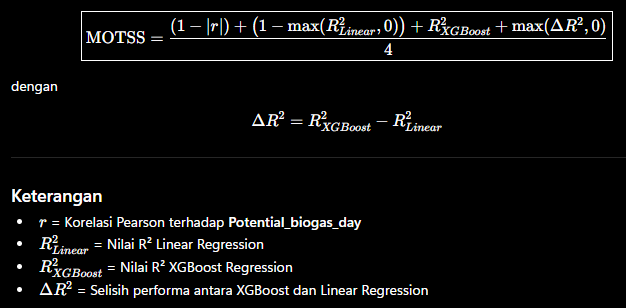

In [ ]:
# ============================================================
# PERHITUNGAN MULTI-OBJECTIVE TARGET SUITABILITY SCORE (MOTSS)
# format long: 1 baris = 1 Target + 1 Model
# ============================================================

# membuat salinan hasil evaluasi
motss_result=candidate_evaluation.copy()

# menghitung independency score
# korelasi rendah terhadap target utama akan menghasilkan score tinggi
motss_result["Independency Score"]=(
    1-motss_result["Correlation with Potential_biogas_day"].abs()
)

# menghitung model performance score
# R² negatif dibuat menjadi 0 agar tidak menurunkan skala score secara ekstrem
motss_result["Model Performance Score"]=motss_result["R²"].clip(lower=0)

# menghitung baseline weakness score
# semakin rendah linear r2, semakin tinggi peluang kandidat cocok untuk pendekatan non-linear
motss_result["Linear Weakness Score"]=(
    1-motss_result["Baseline Linear R²"].clip(lower=0)
)

# menghitung positive delta score
# hanya peningkatan positif terhadap linear yang dihitung
motss_result["Positive Delta R²"]=(
    motss_result["Delta R² vs Linear"].clip(lower=0)
)

# menghitung multi-objective target suitability score
motss_result["MOTSS"]=(
    (
        motss_result["Independency Score"]
    )+
    (
        motss_result["Model Performance Score"]
    )+
    (
        motss_result["Linear Weakness Score"]
    )+
    (
        motss_result["Positive Delta R²"]
    )
)/4

# menentukan pendekatan pemodelan
motss_result["Suggested Modeling Approach"]=np.where(
    motss_result["Delta R² vs Linear"]>0,
    "Non-Linear / Alternative Model",
    "Linear / Baseline"
)

# menentukan tingkat rekomendasi
conditions=[
    motss_result["MOTSS"]>=0.80,
    motss_result["MOTSS"]>=0.60,
    motss_result["MOTSS"]>=0.40
]

choices=[
    "Highly Recommended",
    "Recommended",
    "Consider"
]

motss_result["Recommendation"]=np.select(
    conditions,
    choices,
    default="Not Recommended"
)

# mengurutkan berdasarkan MOTSS
motss_result=motss_result.sort_values(
    by="MOTSS",
    ascending=False
).reset_index(drop=True)

# membuat ranking
motss_result.insert(
    0,
    "Rank",
    range(1,len(motss_result)+1)
)

# memilih kolom yang ditampilkan
motss_result=motss_result[[

    "Rank",
    "Target",
    "Model",

    "Correlation with Potential_biogas_day",

    "R²",
    "MAE",
    "RMSE",

    "Baseline Linear R²",
    "Delta R² vs Linear",

    "Independency Score",
    "Model Performance Score",
    "Linear Weakness Score",
    "Positive Delta R²",

    "Suggested Modeling Approach",
    "MOTSS",
    "Recommendation"

]]

# mengambil model terbaik untuk setiap target berdasarkan MOTSS
motss_best_target=motss_result.sort_values(
    by="MOTSS",
    ascending=False
).drop_duplicates(
    subset=["Target"],
    keep="first"
).reset_index(drop=True)

motss_best_target.insert(
    0,
    "Target Rank",
    range(1,len(motss_best_target)+1)
)

print("="*70)
print("MULTI-OBJECTIVE TARGET SUITABILITY SCORE COMPLETED SUCCESSFULLY")
print("="*70)
print(f"Total Row MOTSS       : {len(motss_result)}")
print(f"Total Candidate Target: {motss_result['Target'].nunique()}")
print(f"Total Model           : {motss_result['Model'].nunique()}")

print("\n"+"="*70)
print("MOTSS RESULT - ROW TERPISAH PER TARGET DAN MODEL")
print("="*70)

display(motss_result)

print("\n"+"="*70)
print("MODEL TERBAIK UNTUK SETIAP TARGET")
print("="*70)

display(motss_best_target)

print("\n"+"="*70)
print("LOGIKA PERHITUNGAN MOTSS")
print("="*70)
print("1. Semakin rendah korelasi terhadap Potential_biogas_day, semakin tinggi Independency Score.")
print("2. Nilai R² setiap model digunakan sebagai Model Performance Score.")
print("3. Baseline Linear R² digunakan untuk menghitung Linear Weakness Score.")
print("4. Delta R² vs Linear dihitung untuk setiap model secara terpisah.")
print("5. MOTSS dihitung pada level Target + Model, sehingga hasil tidak digabung dalam satu row.")

# ============================================================
# MENYIMPAN HASIL MOTSS KE FILE EXCEL
# ============================================================

output_file = "/content/drive/MyDrive/dataset/hasil_MOTSS_multi_model.xlsx"

with pd.ExcelWriter(output_file) as writer:

    motss_result.to_excel(
        writer,
        sheet_name="motss_all_models",
        index=False
    )

    motss_best_target.to_excel(
        writer,
        sheet_name="best_model_per_target",
        index=False
    )

print("\n" + "="*70)
print("HASIL MOTSS BERHASIL DISIMPAN")
print("="*70)
print(f"Nama File : hasil_MOTSS_multi_model.xlsx")
print(f"Lokasi    : {output_file}")


MULTI-OBJECTIVE TARGET SUITABILITY SCORE COMPLETED SUCCESSFULLY
Total Row MOTSS       : 209
Total Candidate Target: 19
Total Model           : 11

MOTSS RESULT - ROW TERPISAH PER TARGET DAN MODEL


,Rank,Target,Model,Correlation with Potential_biogas_day,R²,MAE,RMSE,Baseline Linear R²,Delta R² vs Linear,Independency Score,Model Performance Score,Linear Weakness Score,Positive Delta R²,Suggested Modeling Approach,MOTSS,Recommendation
0,1,non_industrial_feed,CatBoost,-0.072670,0.575752,149.915715,4.470048e+02,-0.805034,1.380785,0.927330,0.575752,1.000000,1.380785,Non-Linear / Alternative Model,0.970967,Highly Recommended
1,2,non_industrial_feed,Gradient Boosting,-0.072670,0.573813,156.543996,4.480252e+02,-0.805034,1.378846,0.927330,0.573813,1.000000,1.378846,Non-Linear / Alternative Model,0.969997,Highly Recommended
2,3,non_industrial_feed,XGBoost,-0.072670,0.516026,173.950471,4.774338e+02,-0.805034,1.321059,0.927330,0.516026,1.000000,1.321059,Non-Linear / Alternative Model,0.941104,Highly Recommended
3,4,non_industrial_feed,AdaBoost,-0.072670,0.478439,170.531940,4.956268e+02,-0.805034,1.283472,0.927330,0.478439,1.000000,1.283472,Non-Linear / Alternative Model,0.922310,Highly Recommended
4,5,non_industrial_feed,Random Forest,-0.072670,0.443932,169.794567,5.117597e+02,-0.805034,1.248965,0.927330,0.443932,1.000000,1.248965,Non-Linear / Alternative Model,0.905057,Highly Recommended
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
204,205,total_ekor_ayam_pedaging,MLP,0.801761,-0.106472,712861.826741,2.298002e+06,0.998887,-1.105359,0.198239,0.000000,0.001113,0.000000,Linear / Baseline,0.049838,Not Recommended
205,206,total_manure_potential_year_chicken_ton,MLP,0.804501,-0.115326,23700.796354,7.366569e+04,1.000000,-1.115326,0.195499,0.000000,0.000000,0.000000,Linear / Baseline,0.048875,Not Recommended
206,207,total_manure_potential_year_chicken_ton,SVR,0.804501,-0.108794,23539.379621,7.344968e+04,1.000000,-1.108794,0.195499,0.000000,0.000000,0.000000,Linear / Baseline,0.048875,Not Recommended
207,208,total_manure_potential_day_chicken_kg,MLP,0.804501,-0.115427,64939.609869,2.018330e+05,1.000000,-1.115427,0.195499,0.000000,0.000000,0.000000,Linear / Baseline,0.048875,Not Recommended



MODEL TERBAIK UNTUK SETIAP TARGET


,Target Rank,Rank,Target,Model,Correlation with Potential_biogas_day,R²,MAE,RMSE,Baseline Linear R²,Delta R² vs Linear,Independency Score,Model Performance Score,Linear Weakness Score,Positive Delta R²,Suggested Modeling Approach,MOTSS,Recommendation
0,1,1,non_industrial_feed,CatBoost,-0.072670,0.575752,1.499157e+02,4.470048e+02,-0.805034,1.380785,0.927330,0.575752,1.000000e+00,1.380785,Non-Linear / Alternative Model,0.970967,Highly Recommended
1,2,7,dairy_cattle,Gradient Boosting,0.033772,0.947231,8.505750e+00,2.680846e+01,0.287583,0.659649,0.966228,0.947231,7.124174e-01,0.659649,Non-Linear / Alternative Model,0.821381,Highly Recommended
2,3,17,beef_cattle,MLP,0.230504,0.687869,3.468333e+01,1.668890e+02,0.197413,0.490456,0.769496,0.687869,8.025866e-01,0.490456,Non-Linear / Alternative Model,0.687602,Recommended
3,4,18,average_temperature_per_district,XGBoost,-0.267464,0.805339,6.864227e-01,9.416536e-01,0.305928,0.499411,0.732536,0.805339,6.940720e-01,0.499411,Non-Linear / Alternative Model,0.682839,Recommended
4,5,34,total_ekor_sapi_daging,Extra Trees,0.101791,0.898211,1.278274e+02,4.217306e+02,0.741391,0.156820,0.898209,0.898211,2.586089e-01,0.156820,Non-Linear / Alternative Model,0.552962,Consider
5,6,35,humidity,Extra Trees,0.263465,0.897132,8.131188e-01,1.183900e+00,0.660462,0.236670,0.736535,0.897132,3.395376e-01,0.236670,Non-Linear / Alternative Model,0.552469,Consider
6,7,49,mixed_feed,Linear Regression,0.008004,0.797927,8.122232e+01,1.661971e+02,0.797927,0.000000,0.991996,0.797927,2.020726e-01,0.000000,Linear / Baseline,0.497999,Consider
7,8,58,layer_chickens,Random Forest,-0.092980,0.759411,1.422806e+00,4.379003e+00,0.753593,0.005818,0.907020,0.759411,2.464072e-01,0.005818,Non-Linear / Alternative Model,0.479664,Consider
8,9,59,broiler_chickens,Linear Regression,-0.086742,0.418709,4.217055e+00,1.474616e+01,0.418709,0.000000,0.913258,0.418709,5.812909e-01,0.000000,Linear / Baseline,0.478314,Consider
9,10,60,industrial_feed,Linear Regression,-0.091808,0.833041,9.070768e+00,1.692261e+01,0.833041,0.000000,0.908192,0.833041,1.669594e-01,0.000000,Linear / Baseline,0.477048,Consider



LOGIKA PERHITUNGAN MOTSS
1. Semakin rendah korelasi terhadap Potential_biogas_day, semakin tinggi Independency Score.
2. Nilai R² setiap model digunakan sebagai Model Performance Score.
3. Baseline Linear R² digunakan untuk menghitung Linear Weakness Score.
4. Delta R² vs Linear dihitung untuk setiap model secara terpisah.
5. MOTSS dihitung pada level Target + Model, sehingga hasil tidak digabung dalam satu row.

HASIL MOTSS BERHASIL DISIMPAN
Nama File : hasil_MOTSS_multi_model.xlsx
Lokasi    : /content/drive/MyDrive/dataset/hasil_MOTSS_multi_model.xlsx


In [ ]:
# ============================================================
# STAGE 13
# EVALUASI KELAYAKAN KANDIDAT TARGET BERDASARKAN DOMAIN
# ============================================================

# jumlah kandidat yang ditampilkan
top_candidate = 5

# deskripsi setiap variabel
variable_description = {

    "year":"Tahun pengamatan.",

    "district":"Nama kabupaten/kota lokasi pengamatan.",

    "subdistrict":"Nama kecamatan lokasi pengamatan.",

    "beef_cattle":"Kode atau kategori populasi sapi potong.",

    "dairy_cattle":"Kode atau kategori populasi sapi perah.",

    "layer_chickens":"Kode atau kategori populasi ayam petelur.",

    "broiler_chickens":"Kode atau kategori populasi ayam pedaging.",

    "total_ekor_sapi_perah":"Total populasi sapi perah (ekor).",

    "total_ekor_sapi_daging":"Total populasi sapi potong (ekor).",

    "total_ekor_ayam_petelur":"Total populasi ayam petelur (ekor).",

    "total_ekor_ayam_pedaging":"Total populasi ayam pedaging (ekor).",

    "Manure_per_animal_sapiPerah":"Produksi kotoran per ekor sapi perah per hari (kg/ekor/hari).",

    "Manure_per_animal_sapiPotong":"Produksi kotoran per ekor sapi potong per hari (kg/ekor/hari).",

    "manure_per_animal_chicken_layer":"Produksi kotoran per ekor ayam petelur per hari (kg/ekor/hari).",

    "manure_per_animal_chicken_potong":"Produksi kotoran per ekor ayam pedaging per hari (kg/ekor/hari).",

    "total_manure_potential_day_cattle_kg":"Total potensi kotoran sapi per hari (kg/hari).",

    "total_manure_potential_year_cattle_ton":"Total potensi kotoran sapi per tahun (ton/tahun).",

    "total_manure_potential_day_chicken_kg":"Total potensi kotoran ayam per hari (kg/hari).",

    "total_manure_potential_year_chicken_ton":"Total potensi kotoran ayam per tahun (ton/tahun).",

    "non_industrial_feed":"Jumlah atau penggunaan pakan non-industri, seperti hijauan atau limbah pertanian.",

    "mixed_feed":"Jumlah atau penggunaan pakan campuran.",

    "industrial_feed":"Jumlah atau penggunaan pakan industri atau pakan pabrikan.",

    "average_temperature_per_district":"Rata-rata suhu udara wilayah pengamatan (°C).",

    "humidity":"Rata-rata kelembapan udara (%).",

    "Average_daily_rainfall":"Rata-rata curah hujan harian (mm/hari).",

    "total_rainfall":"Total curah hujan selama periode pengamatan (mm).",

    "crude_oil_price_usd_avg":"Rata-rata harga minyak mentah dunia (USD).",

    "usd_idr_avg":"Rata-rata nilai tukar Dolar Amerika terhadap Rupiah.",

    "energy_price_proxy_idr":"Indikator atau proksi harga energi dalam Rupiah.",

    "Potential_biogas_day":"Estimasi potensi produksi biogas per hari."
}

candidate_domain = motss_best_target.head(top_candidate).copy()

print("="*70)
print("EVALUASI KELAYAKAN KANDIDAT TARGET BERDASARKAN DOMAIN")
print("="*70)

for i, row in candidate_domain.iterrows():

    variable = row["Target"]

    print(f"\nKANDIDAT {i+1}")
    print("-"*70)

    print(f"Nama Variabel               : {variable}")

    print(f"Deskripsi                  : {variable_description.get(variable,'Deskripsi belum tersedia.')}")

    print(f"Nilai MOTSS                : {row['MOTSS']:.3f}")

    print(f"Korelasi terhadap Y Utama  : {row['Correlation with Potential_biogas_day']:.3f}")

    print(f"Pendekatan Pemodelan       : {row['Suggested Modeling Approach']}")

    print(f"Rekomendasi                : {row['Recommendation']}")

    print("\nChecklist Evaluasi Domain")

    print("[ ] Variabel memiliki makna operasional dalam sistem.")

    print("[ ] Variabel dapat dijadikan objective optimasi.")

    print("[ ] Variabel tidak redundan terhadap objective utama.")

    print("[ ] Variabel relevan dengan tujuan penelitian.")

    print("[ ] Variabel memungkinkan dilakukan proses optimasi.")

    print("[ ] Arah objective telah ditentukan (Maksimasi / Minimasi).")

    print("[ ] Variabel layak dipromosikan menjadi target tambahan (Y₂, Y₃, dan seterusnya).")

    print("-"*70)

print("\n"+"="*70)
print("KESIMPULAN")
print("="*70)

print("Tahap ini merupakan evaluasi berbasis domain penelitian sebagai")
print("pelengkap hasil pemeringkatan menggunakan Multi-Objective Target")
print("Suitability Score (MOTSS).")

print("\nKeputusan akhir pemilihan variabel target tambahan tidak hanya")
print("ditentukan oleh nilai MOTSS, tetapi juga mempertimbangkan")

print("- Makna operasional variabel.")
print("- Relevansi terhadap tujuan penelitian.")
print("- Kesesuaian sebagai objective optimasi.")
print("- Penentuan arah objective (maksimasi atau minimasi).")
print("- Pertimbangan ilmiah dari peneliti.")

EVALUASI KELAYAKAN KANDIDAT TARGET BERDASARKAN DOMAIN

KANDIDAT 1
----------------------------------------------------------------------
Nama Variabel               : non_industrial_feed
Deskripsi                  : Jumlah atau penggunaan pakan non-industri, seperti hijauan atau limbah pertanian.
Nilai MOTSS                : 0.971
Korelasi terhadap Y Utama  : -0.073
Pendekatan Pemodelan       : Non-Linear / Alternative Model
Rekomendasi                : Highly Recommended

Checklist Evaluasi Domain
[ ] Variabel memiliki makna operasional dalam sistem.
[ ] Variabel dapat dijadikan objective optimasi.
[ ] Variabel tidak redundan terhadap objective utama.
[ ] Variabel relevan dengan tujuan penelitian.
[ ] Variabel memungkinkan dilakukan proses optimasi.
[ ] Arah objective telah ditentukan (Maksimasi / Minimasi).
[ ] Variabel layak dipromosikan menjadi target tambahan (Y₂, Y₃, dan seterusnya).
----------------------------------------------------------------------

KANDIDAT 2
--------------

### MENYIMPAN DATASET FINAL UNTUK PIPELINE PENELITIAN UTAMA

In [ ]:
# ============================================================
# STAGE 14
# MENYIMPAN DATASET FINAL UNTUK PIPELINE PENELITIAN UTAMA
# ============================================================

# nama target utama
target_column = "Potential_biogas_day"

# variabel yang selalu ditempatkan di sebelah kiri
fixed_columns = [
    "year",
    "district",
    "subdistrict",
    "Manure_per_animal_sapiPerah",
    "Manure_per_animal_sapiPotong",
    "manure_per_animal_chicken_layer",
    "manure_per_animal_chicken_potong"
]

# variabel X berdasarkan ranking target terbaik dari MOTSS
# menggunakan motss_best_target agar nama target tidak duplikat akibat evaluasi multi-model
motss_columns = motss_best_target["Target"].tolist()

# menghapus target utama jika ada
motss_columns = [
    col for col in motss_columns
    if col != target_column
]

# menghapus kolom fixed jika muncul lagi pada motss_columns
motss_columns = [
    col for col in motss_columns
    if col not in fixed_columns
]

# mencari kolom yang belum masuk
remaining_columns = [
    col for col in df_clean.columns
    if col not in fixed_columns
    and col not in motss_columns
    and col != target_column
]

# membentuk urutan akhir kolom
final_columns = (
    fixed_columns +
    motss_columns +
    remaining_columns +
    [target_column]
)

# memastikan tidak ada nama kolom duplikat
final_columns = list(dict.fromkeys(final_columns))

# membuat dataset final
dataset_final = df_clean[final_columns].copy()

# menyimpan ke Google Drive
output_file = "/content/drive/MyDrive/dataset/dataset_pipeline_penelitian_utama.xlsx"

dataset_final.to_excel(
    output_file,
    index=False
)

print("="*70)
print("DATASET FINAL BERHASIL DIBUAT")
print("="*70)

print(f"Nama File : dataset_pipeline_penelitian_utama.xlsx")
print(f"Lokasi    : {output_file}")

print(f"\nJumlah Baris : {dataset_final.shape[0]}")
print(f"Jumlah Kolom : {dataset_final.shape[1]}")

print("\nUrutan Kolom Dataset")

for i, col in enumerate(dataset_final.columns, start=1):
    print(f"{i:>2}. {col}")

# validasi jumlah kolom
print("\n" + "="*70)
print("VALIDASI DATASET")
print("="*70)

missing_columns = set(df_clean.columns) - set(final_columns)

if len(missing_columns) == 0:
    print("✓ Tidak ada kolom yang hilang.")
else:
    print("\nKolom yang hilang:")
    for col in sorted(missing_columns):
        print("-", col)

duplicate_columns = pd.Series(final_columns).duplicated().sum()

if duplicate_columns == 0:
    print("✓ Tidak ada kolom duplikat.")
else:
    print(f"✗ Terdapat {duplicate_columns} kolom duplikat.")


DATASET FINAL BERHASIL DIBUAT
Nama File : dataset_pipeline_penelitian_utama.xlsx
Lokasi    : /content/drive/MyDrive/dataset/dataset_pipeline_penelitian_utama.xlsx

Jumlah Baris : 774
Jumlah Kolom : 30

Urutan Kolom Dataset
 1. year
 2. district
 3. subdistrict
 4. Manure_per_animal_sapiPerah
 5. Manure_per_animal_sapiPotong
 6. manure_per_animal_chicken_layer
 7. manure_per_animal_chicken_potong
 8. non_industrial_feed
 9. dairy_cattle
10. beef_cattle
11. average_temperature_per_district
12. total_ekor_sapi_daging
13. humidity
14. mixed_feed
15. layer_chickens
16. broiler_chickens
17. industrial_feed
18. total_ekor_ayam_petelur
19. Average_daily_rainfall
20. total_rainfall
21. total_ekor_sapi_perah
22. total_manure_potential_year_cattle_ton
23. total_manure_potential_day_cattle_kg
24. total_ekor_ayam_pedaging
25. total_manure_potential_year_chicken_ton
26. total_manure_potential_day_chicken_kg
27. crude_oil_price_usd_avg
28. usd_idr_avg
29. energy_price_proxy_idr
30. Potential_biogas_d